# Scan Time and Signal-to-Noise Ratio (SNR)

**Part:** G – Image characteristics · **Reading time:** ~60 min · **Pass 1 overview:** [Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [Fourier properties (Parseval)](../refreshers/RM4_Fourier_Properties.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb), [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb), [Spin and thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)

**Why this chapter matters.** Every MRI protocol is a negotiation between three things: how *sharp* the image is (resolution), how *long* the patient lies in the scanner (scan time) and how *clean* the image is (SNR). Unlike many imaging methods, MRI has a simple and very accurate rule for how SNR depends on the parameters you choose. With it you can predict, before scanning, whether a protocol change will give a usable image. This chapter derives that rule step by step, explains where the noise physically comes from, and shows with simulations how to measure SNR correctly (including the traps of magnitude images).

## Learning goals

1. Understand the constraints and trade-offs in MRI
    * Determine how long a scan takes
    * Describe the factors that influence image SNR
    * Explain where MRI noise comes from and why it is Gaussian and white
1. Manipulate MRI sequence parameters to improve performance
    * Understand how modifications in sequence parameters will affect the total scan time and expected SNR
    * Predict the SNR change from averaging, bandwidth and resolution changes, and verify it with a simulation
1. Measure SNR in an image correctly
    * Know the bias of magnitude images (Rician/Rayleigh statistics) and the standard measurement methods

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $SNR$ | signal-to-noise ratio: mean signal in a region divided by noise standard deviation | – | 10–100 in clinical images |
| $SNR_{eff}$ | SNR efficiency: SNR per square root of scan time | s$^{-1/2}$ | for comparing sequences |
| $\sigma_k$ | noise standard deviation of **one k-space sample** (per real or imaginary part) | a.u. (V) | set by bandwidth and coil |
| $\sigma_n$ | noise standard deviation of **one image pixel** (per real or imaginary part) | a.u. | |
| $A$ | true (noise-free) signal amplitude of a pixel | a.u. | |
| $\hat m$, $\lvert\hat m\rvert$ | reconstructed (complex) image; its magnitude | a.u. | |
| $T_{scan}$ | total scan time | s | seconds to ~10 min |
| $TR$ | repetition time | s | 3 ms – 10 s |
| $TE$ | echo time | s | 1–100 ms |
| $N_{TR}$ | total number of TRs (repetitions) in the scan | – | |
| $N_{PE}$ | number of phase-encoding steps | – | 128–512 |
| $N_{read}$ | number of readout (frequency-encoding) samples; the original writes $N_{FE}$ | – | 128–512 |
| $NEX$ | number of excitations = number of averages (original: $N_{averages}$, also called NSA) | – | 1–4 |
| $\Delta t$ | dwell time: time between two ADC samples | s | 2–20 µs |
| $T_{read}=N_{read}\Delta t$ | duration of one readout | s | 2–10 ms |
| $T_{meas}$ | total time the ADC is sampling for one image | s | |
| $BW_{read}=1/\Delta t$ | receiver bandwidth (total, i.e. "$\pm BW_{read}/2$") | Hz | 32–500 kHz |
| $BW_{pix}=BW_{read}/N_{read}=1/T_{read}$ | bandwidth per pixel | Hz/pixel | 100–1000 Hz |
| $\delta_x,\delta_y,\delta_z$ | voxel dimensions (spatial resolution); $\delta_z$ = slice thickness $\Delta z$ in 2D | m | 0.5–5 mm |
| $\Delta V=\delta_x\delta_y\delta_z$ | voxel volume | m³ | 1 mm³ = $10^{-9}$ m³ |
| $FOV$ | field of view, $FOV=N\delta$ | m | 0.2–0.5 m |
| $N$ | matrix size (samples per dimension) | – | |
| $f_{seq}$ | "sequence factor": transverse magnetization at TE, relative to $M_0$ | – | 0–1 |
| $M_0$ | equilibrium magnetization (normalized to 1 for pure water) | – | |
| $\theta$ | flip angle | rad | |
| $T_1$, $T_2^*$ | longitudinal / effective transverse relaxation **time constants** | s | |
| $E_1=e^{-TR/T_1}$ | shorthand | – | |
| $B_0$ | main magnetic field | T | 1.5, 3 T |
| $\omega_0=2\pi f_0=\gamma B_0$ | Larmor angular frequency | rad/s | $2\pi\cdot127.7$ MHz at 3 T |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio (rad s⁻¹ T⁻¹), $\bar\gamma=\gamma/2\pi$ (Hz/T) | | 42.58 MHz/T for ¹H |
| $k_B$ | Boltzmann constant | J/K | $1.381\times10^{-23}$ |
| $T$ (no subscript) | absolute temperature | K | 310 K body (**not** tesla, **not** $T_1$) |
| $R_{coil}$, $R_{body}$, $R_{tot}$ | equivalent noise resistance of coil, of the body, total | Ω | ~0.1–10 Ω |
| $v_n$ | rms thermal noise voltage | V | tens of nV |
| $R$, $g$ | parallel-imaging acceleration factor; g-factor ($\ge1$) | – | **clash**: $R$ resistance – we always write $R_{coil}$/$R_{body}$ for resistance |
| $\Delta f_{cs}$ | chemical-shift frequency difference fat–water | Hz | ≈ −440 Hz at 3 T |
| $I_0, I_1$ | modified Bessel functions of the first kind (in the Rice distribution) | – | **not** spin number $I$ |
| $N_{avg}$ | number of independent samples averaged in a derivation | – | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## Scan time

The total scan time, $T_{scan}$, depends on the length of each building block of the pulse sequence and on how many times these blocks are repeated. For sequences made of one repeated block of length $TR$:

$$T_{scan} = TR \cdot N_{TR}$$

**In words:** the scan lasts as long as one repetition times the number of repetitions.

where
* $TR$ [s] = repetition time (time from one excitation to the next),
* $N_{TR}$ [–] = total number of TRs. It depends on the number of phase encodes $N_{PE}$, on preparation or **dummy** cycles (TRs played only to reach the steady state, no data kept), on the acceleration factor $R$ of parallel imaging (fewer phase encodes, see [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb)) and on the number of averages $NEX$.

For a plain, unaccelerated 2D Cartesian scan: $N_{TR}=N_{PE}\cdot NEX$, so e.g. $TR=500$ ms, $N_{PE}=256$, $NEX=1$ gives $T_{scan}=128$ s ≈ 2 min 8 s. (Multi-slice imaging fits many slices into one TR, so they come "for free" – see [Volumetric Imaging](H1_Volumetric_Imaging.ipynb) and [Cartesian Image Characteristics](G3_Cartesian_Image_Characteristics.ipynb).)

## Where does MRI noise come from?

Before discussing how SNR depends on parameters we need to know what the noise *is*.

The receive coil is a loop of wire connected to an amplifier. The precessing magnetization induces a tiny voltage in it (Faraday induction, see [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb)). But *any* conductor at a temperature $T>0$ also produces a random voltage: its electrons jiggle thermally. This is **thermal (Johnson–Nyquist) noise**. A resistance $R_{tot}$ at temperature $T$, observed through a receiver of bandwidth $BW_{read}$, shows an rms noise voltage

$$v_n = \sqrt{4\,k_B\,T\,R_{tot}\,BW_{read}}$$

**In words:** the noise voltage grows with temperature, with the resistance "seen" by the coil, and with the square root of the frequency band you listen to.

where
* $k_B=1.381\times10^{-23}$ J/K is the Boltzmann constant, $T$ [K] the absolute temperature (≈310 K for the body),
* $R_{tot}=R_{coil}+R_{body}$ [Ω] is the total equivalent resistance seen at the coil terminals,
* $BW_{read}$ [Hz] the receiver bandwidth.

Two resistances contribute:
1. **The coil itself** ($R_{coil}$): copper loss of the wire, capacitors, solder joints.
2. **The patient** ($R_{body}$): tissue is an electrical conductor (salt water, conductivity ~0.5 S/m). Thermally fluctuating currents in the body induce noise voltages in the coil – the same coupling (reciprocity) by which the coil picks up the MR signal. At 1.5 T and above, for human-sized coils, the **body noise dominates**: the patient is the noise source.

A third contribution, the **preamplifier**, adds a little noise on top (expressed by its *noise figure*, typically 0.5 dB, i.e. ~12% extra noise power). Details are in [RF System and Receive Chain](B5_RF_System_and_Receive_Chain.ipynb).

> **🧭 Intuition:** Listening for the MR signal is like listening for a whisper in a room full of murmuring people. The murmur (thermal noise) is spread evenly over all frequencies ("white"). If you listen to a narrower frequency band (low bandwidth) you hear less murmur – but then you must listen longer to hear the whole sentence.

In [2]:
# Order-of-magnitude numbers for thermal noise (illustrative values)
kB = mt.K_BOLTZMANN      # [J/K]
T_body = 310.0           # [K]
R_tot = 2.0              # [Ohm]  equivalent loaded-coil resistance (order of magnitude, assumed)
for BW in [16e3, 64e3, 250e3]:     # receiver bandwidth [Hz]
    vn = np.sqrt(4 * kB * T_body * R_tot * BW)
    print(f"BW_read = {BW/1e3:6.0f} kHz  ->  v_n = {vn*1e9:5.1f} nV rms")

BW_read =     16 kHz  ->  v_n =  23.4 nV rms
BW_read =     64 kHz  ->  v_n =  46.8 nV rms
BW_read =    250 kHz  ->  v_n =  92.5 nV rms


A few tens of nanovolts – while the MR signal from a voxel is of the same order or smaller, which is why the receive chain needs low-noise preamplifiers directly at the coil. Note the $\sqrt{BW}$ scaling: 4× the bandwidth → 2× the noise voltage.

### Properties of MRI noise

From the physics above follow three properties that make MRI noise mathematically convenient:

1. **Gaussian, zero mean.** It is the sum of the motion of an enormous number of electrons → central limit theorem.
2. **Complex and circular.** The receiver demodulates the signal into a real ("in-phase", I) and an imaginary ("quadrature", Q) channel. Both receive independent Gaussian noise with the *same* standard deviation $\sigma_k$. We model one k-space sample as
   $$s_{meas} = s + \sigma_k\,(\nu_1 + i\,\nu_2), \qquad \nu_1,\nu_2 \sim \mathcal N(0,1)\ \text{independent}$$
   **In words:** each measured sample is the true sample plus a random complex number whose real and imaginary parts are independent standard Gaussians scaled by $\sigma_k$. (This is exactly what `mt.add_complex_noise(x, sigma)` does.)
3. **White.** Noise in different samples is independent (uncorrelated), and its variance per sample is proportional to the bandwidth: $\sigma_k^2 \propto BW_{read} = 1/\Delta t$.

**Consequence for the image (Cartesian, single coil):** the inverse DFT is (up to a scale factor) a unitary transform. Unitary transforms keep white Gaussian noise white and Gaussian, and they preserve total noise energy ([Parseval's theorem](../refreshers/RM4_Fourier_Properties.ipynb)). So the image noise is **also complex Gaussian, uniform across the whole image, independent between pixels**. With the orthonormal centered FFT `mt.ifft2c` (`norm="ortho"`), a k-space noise std of $\sigma_k$ becomes an image noise std of exactly $\sigma_k$ per pixel. Let us check that numerically.

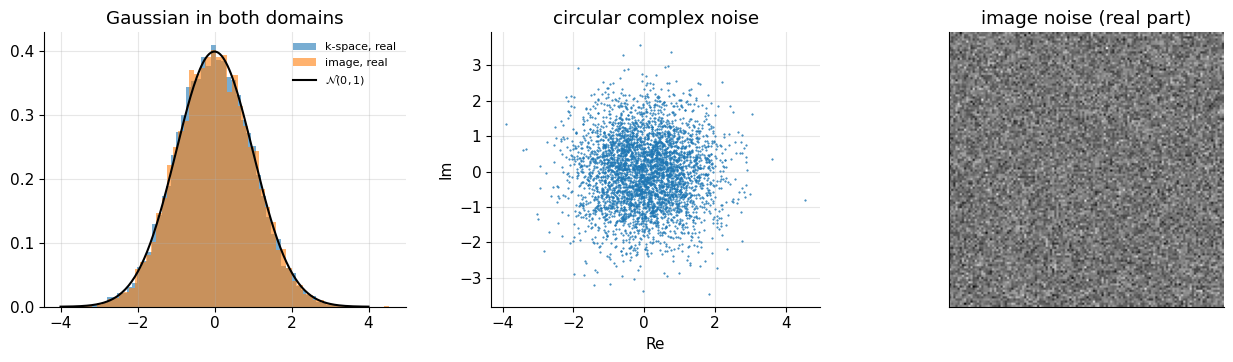

std k-space (real) = 0.995,  std image (real) = 0.991, std image (imag) = 0.990


In [3]:
rng = np.random.default_rng(1)
N = 128
sigma_k = 1.0
noise_k = mt.add_complex_noise(np.zeros((N, N)), sigma_k, rng=rng)  # pure noise k-space
noise_img = mt.ifft2c(noise_k)                                       # orthonormal inverse FFT

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(noise_k.real.ravel(), 60, density=True, alpha=0.6, label="k-space, real")
ax[0].hist(noise_img.real.ravel(), 60, density=True, alpha=0.6, label="image, real")
x = np.linspace(-4, 4, 200)
ax[0].plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k", label=r"$\mathcal{N}(0,1)$")
ax[0].legend(fontsize=8); ax[0].set_title("Gaussian in both domains")
ax[1].plot(noise_img.real.ravel()[:4000], noise_img.imag.ravel()[:4000], ".", ms=1)
ax[1].set_aspect("equal"); ax[1].set_xlabel("Re"); ax[1].set_ylabel("Im"); ax[1].set_title("circular complex noise")
mt.show_image(noise_img.real, ax=ax[2], title="image noise (real part)")
plt.tight_layout(); plt.show()
print(f"std k-space (real) = {noise_k.real.std():.3f},  std image (real) = {noise_img.real.std():.3f}, "
      f"std image (imag) = {noise_img.imag.std():.3f}")

Both histograms coincide with the standard normal curve, the complex cloud is round, and the image noise has no visible structure: the image noise has the same std as the k-space noise (orthonormal FFT).

## SNR dependencies

The SNR depends on factors we control in an MRI experiment through three factors:

1. Voxel volume
2. Data acquisition time
3. Transverse magnetization (the "sequence factor")

Other system factors also influence SNR, such as the magnetic field strength and the RF coils; they are treated at the end of the chapter.

### Voxel volume

The MRI signal is an integral over a volume of the transverse magnetization (see the [MRI Signal Equation](C2_MRI_Signal_Equation.ipynb)). The signal of one voxel is therefore proportional to the amount of magnetization in it, i.e. to its volume:

$$SNR \propto \Delta V = \delta_x\, \delta_y\, \delta_z$$

**In words:** twice the voxel volume holds twice the spins and gives twice the signal; the noise (which comes from the whole body and coil, not from the voxel) stays the same.

where $\delta_x, \delta_y, \delta_z$ [m] are the voxel dimensions in x, y and z (in 2D imaging $\delta_z$ is the slice thickness $\Delta z$). Example: going from $1\times1\times3$ mm³ to $0.5\times0.5\times3$ mm³ divides the voxel volume, and the SNR, by 4.

### Data acquisition time

Every additional measurement allows for signal averaging, because the noise is different in each measurement while the signal is the same. MRI noise is zero-mean and Gaussian (see above). If the total measurement time grows by a factor, the summed signal grows linearly with it but the summed noise only with its square root. So

$$SNR \propto \frac{S}{\sigma} \propto \frac{T_{meas}}{\sqrt{T_{meas}}} = \sqrt{T_{meas}}$$

**In words:** SNR grows with the square root of the total time spent sampling data.

where $T_{meas}$ [s] is the *total data acquisition (measurement) time*, including all TRs and signal averages, but **not** including the sequence "downtime" (RF pulses, phase encoding, spoiling, waiting for $T_1$ recovery). With the readout duration per TR, $T_{read}$, and the total number of TRs, $N_{TR}$ (which e.g. includes the number of phase-encoding steps and averages),

$$T_{meas} = N_{TR}\, T_{read}$$

**In words:** the ADC is on for $T_{read}$ in each of the $N_{TR}$ repetitions.

<details><summary><b>📐 Derivation (optional): why averaging N samples gives √N</b></summary>

Measure the same quantity $N_{avg}$ times: $y_j = A + n_j$, with independent noise $n_j$ of mean 0 and variance $\sigma^2$. Average them:

$$\bar y = \frac{1}{N_{avg}}\sum_{j=1}^{N_{avg}} y_j = A + \frac{1}{N_{avg}}\sum_j n_j .$$

The signal part is still $A$. The variance of a sum of *independent* variables is the sum of the variances, and a factor $c$ in front multiplies the variance by $c^2$:

$$\mathrm{Var}\Big(\frac{1}{N_{avg}}\sum_j n_j\Big) = \frac{1}{N_{avg}^2}\, N_{avg}\,\sigma^2 = \frac{\sigma^2}{N_{avg}}.$$

So the noise std is $\sigma/\sqrt{N_{avg}}$ and $SNR = A\sqrt{N_{avg}}/\sigma$.

**The same argument applies to an image pixel.** A Fourier reconstruction is a weighted sum of *all* $N_{TR}\cdot N_{read}$ k-space samples with weights of magnitude 1 (the phase factors $e^{+i2\pi\vec k\cdot\vec r}$). For the pixel at $\vec r$, the phase factors exactly undo the encoding phase of the voxel at $\vec r$, so its signal adds *coherently* (linearly in the number of samples), while the noise adds *incoherently* (as the square root). Hence

$$SNR_{pixel} \propto \frac{\Delta V \sqrt{N_{TR} N_{read}}}{\sigma_k}.$$

Finally, $\sigma_k^2\propto BW_{read}=1/\Delta t$ (white noise: the variance per sample is proportional to the bandwidth, i.e. inversely proportional to how long each sample "integrates"). Substituting $\sigma_k\propto 1/\sqrt{\Delta t}$:

$$SNR \propto \Delta V \sqrt{N_{TR}\,N_{read}\,\Delta t} = \Delta V \sqrt{N_{TR}\,T_{read}} = \Delta V\sqrt{T_{meas}}.$$

Everything collapses onto the single quantity $T_{meas}$: it does not matter whether you get it by more phase encodes, more averages, more readout samples or a longer dwell time.

</details>

### Transverse magnetization

The MRI signal is also proportional to the transverse magnetization at the echo time, which is modulated by sequence parameters such as TE, TR, flip angle, spin echo versus gradient echo, etc. This in turn depends on the tissue's MR properties such as proton density, relaxation **times** (the original says "rates"; $T_1$, $T_2$ are time constants), diffusion coefficients, etc. Since this varies widely between pulse sequences, we summarize it as

$$SNR \propto f_{seq}$$

**In words:** the sequence factor is "how much of the available magnetization the sequence turns into signal at TE".

For example, in a simple spoiled gradient-echo pulse sequence (derived in [Basic Contrast Mechanisms](D1_Basic_Contrast_Mechanisms.ipynb)):

$$f_{seq,GRE} = M_0 \sin(\theta) \frac{1- e^{-TR/T_1}}{1- \cos(\theta)\, e^{-TR/T_1}}\; e^{-TE/T_2^*}$$

**In words:** the steady-state longitudinal magnetization, tipped by $\sin\theta$ into the transverse plane, decaying with $T_2^*$ until the echo.

where $M_0$ = equilibrium magnetization (proton density), $\theta$ = flip angle, $TR$, $TE$ = repetition and echo time, $T_1$, $T_2^*$ = relaxation time constants. (The original omits the $e^{-TE/T_2^*}$ factor, i.e. it assumes $TE\ll T_2^*$.)

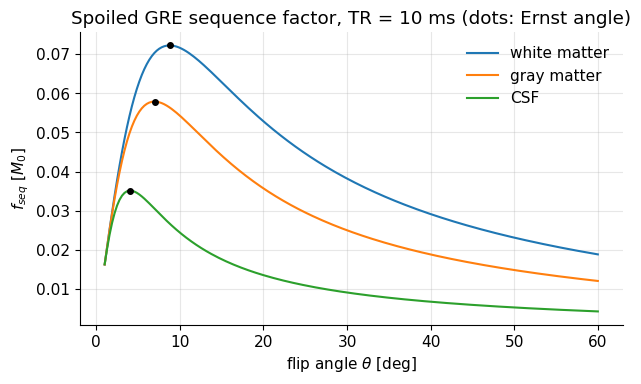

In [4]:
# f_seq for spoiled GRE at 3 T (approximate tissue values; times in seconds)
TR, TE = 10e-3, 3e-3
flips = np.deg2rad(np.linspace(1, 60, 200))
tissues = {"white matter": (0.85, 0.050), "gray matter": (1.35, 0.060), "CSF": (4.0, 0.5)}  # (T1, T2*)
plt.figure(figsize=(7, 3.8))
for name, (T1, T2s) in tissues.items():
    f = mt.spoiled_gre_signal(flips, TE, TR, T1, T2s)
    plt.plot(np.rad2deg(flips), f, label=name)
    thE = mt.ernst_angle(TR, T1)
    plt.plot(np.rad2deg(thE), mt.spoiled_gre_signal(thE, TE, TR, T1, T2s), "ko", ms=4)
plt.xlabel(r"flip angle $\theta$ [deg]"); plt.ylabel(r"$f_{seq}$ [$M_0$]")
plt.title("Spoiled GRE sequence factor, TR = 10 ms (dots: Ernst angle)"); plt.legend(); plt.show()

With a short TR the sequence factor is only a few percent of $M_0$ and peaks at the (small) Ernst angle: $f_{seq}$ can easily change SNR by a factor 5–10, more than any geometric parameter.

## SNR equation

Putting it all together:

$$SNR \propto f_{seq}\cdot \Delta V\cdot \sqrt{T_{meas}} = f_{seq}\;\delta_x\delta_y\delta_z\;\sqrt{N_{TR}\,T_{read}}$$

**In words:** SNR is proportional to how much magnetization the sequence turns into signal, times the volume of a voxel, times the square root of the time the ADC is listening.

where all symbols are as defined above. The proportionality constant contains the field strength, the coil and the patient (see the end of the chapter); when you compare two protocols on the same scanner, coil and patient it cancels.

**This simple equation describes the majority of SNR effects in MRI, and is extremely powerful when designing and improving MRI scans!**

> **⚠️ Common confusion:** The equation is about the SNR *of the acquired data*. Anything you do *after* the acquisition (interpolation, filtering, downsampling) changes the apparent SNR in a different way – see "Resolution and SNR in post-processing" below.

### Alternative formulations of SNR

MRI scanner interfaces often do not let you set resolution or measurement time directly, but ask instead for matrix sizes, FOVs and receiver bandwidths. The following relationships convert these parameters into the SNR equation above:

$$ FOV = \delta \cdot N $$

**In words:** the field of view is the pixel size times the number of pixels (per dimension; derived in [FOV and Resolution](G1_FOV_and_Resolution.ipynb)).

$$ T_{read} = N_{read}\,\Delta t = \frac{N_{read}}{BW_{read}} = \frac{N_{read}}{2\, BW_{one\text{-}sided}} $$

**In words:** the readout lasts (number of samples) × (time per sample), and the time per sample is the inverse of the total bandwidth.

where $BW_{read}=1/\Delta t$ is the **total** receiver bandwidth and $BW_{one\text{-}sided}=BW_{read}/2$ is the "±" value. GE scanners quote the one-sided value ("±31.25 kHz"), Siemens quotes bandwidth *per pixel* ("Hz/Px"), Philips quotes "water–fat shift in pixels". All describe the same thing. Example: $N_{read}=256$, $BW_{read}=64$ kHz (= ±32 kHz) → $\Delta t=15.6$ µs, $T_{read}=4.0$ ms, $BW_{pix}=250$ Hz/pixel.

If acceleration methods such as partial Fourier, parallel imaging or compressed sensing are NOT used, the following relationships also apply:

$$ T_{read} = \frac{N_{read}}{BW_{read}} = \frac{1}{BW_{pix}} $$

$$ N_{TR} = N_{PE} \cdot NEX $$

**In words:** the readout lasts one over the bandwidth per pixel; and there is one TR per phase-encoding step and per average.

> **Correction to the original:** the original writes $N_{TR}=N_{FE}\,N_{PE}\,N_{averages}$. The number of readout samples $N_{FE}$ ($=N_{read}$) does **not** multiply the number of TRs – all readout samples are collected within one TR. The readout samples enter through $T_{read}$ instead: $T_{meas}=N_{PE}\cdot NEX\cdot N_{read}\,\Delta t$.

Substituting everything gives a version of the SNR equation in "scanner parameters" (worked out fully in [Cartesian Image Characteristics](G3_Cartesian_Image_Characteristics.ipynb)):

$$SNR \propto f_{seq}\;\delta_x\delta_y\delta_z\;\sqrt{\frac{N_{PE}\cdot NEX}{BW_{pix}}}$$

**In words:** at fixed voxel size, SNR improves with more phase encodes, more averages and a *lower* bandwidth per pixel.

Partial Fourier methods reduce the readout time or the number of encoding steps, and parallel imaging/compressed sensing reduce the number of encoding steps, lowering $T_{meas}$ and therefore SNR (parallel imaging additionally by the g-factor: $SNR_{acc}=SNR/(g\sqrt R)$, see [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb)).

## Testing the SNR equation by simulation

We now build a small "virtual scanner" that obeys the physics above. The trick is to get the **scaling** right, so that changing the matrix size changes signal and noise the way a real scanner would.

* Object: three disks with signal 1.0, 0.6 and 0.3 (FOV = 1 in arbitrary length units). We use the **analytic** k-space of disks (`mt.disk_phantom_kspace`), so the object is the same continuous object for any matrix size $N$.
* Each k-space sample $s(\vec k)=\int m(\vec r)e^{-i2\pi\vec k\cdot\vec r}d\vec r$ is independent of $N$ (it only depends on where in k-space we are), and gets complex noise with std $\sigma_k\propto\sqrt{BW_{read}}$.
* Reconstruction approximates the inverse Fourier integral by a sum, $\hat m(\vec r)=\Delta k_x\Delta k_y\sum s\,e^{+i2\pi\vec k\cdot\vec r}$, so the image has the physical signal level (1.0 in the brightest disk) independent of $N$.

`mt.disk_phantom_kspace(N)` returns k-space scaled such that `mt.ifft2c` of it gives unit amplitude; the physical sample values are that array divided by $N$, and the physical recon is $N\cdot$`ifft2c`. Then image noise std $\sigma_n = N\sigma_k/\sqrt{NEX}$: for fixed FOV, more pixels = smaller voxels = relatively more noise.

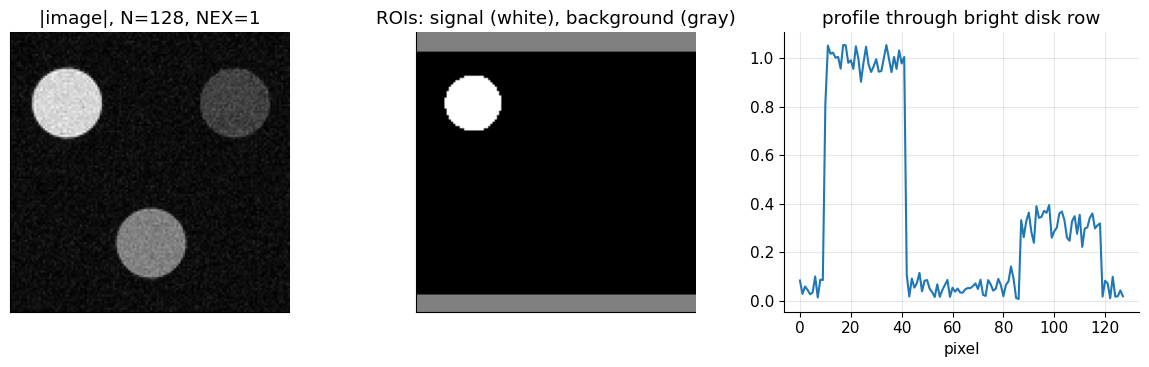

mean signal in ROI = 1.002 (truth 1.0);  noise std = 0.0493 (theory 0.0500);  SNR = 20.3


In [5]:
DISK_VALUES = (1.0, 0.6, 0.3)

def acquire(N=128, BW_rel=1.0, NEX=1, T_read_rel=None, sigma_k0=0.05 / 128, rng=None):
    """Virtual 2D Cartesian acquisition of the 3-disk phantom (FOV = 1).

    N          : matrix size N x N (N_read = N_PE = N), FOV fixed
    BW_rel     : receiver bandwidth BW_read relative to the reference (sets sigma_k ~ sqrt(BW))
    NEX        : number of averages (independent noise realizations, averaged)
    sigma_k0   : per-sample noise std at the reference bandwidth (chosen so that the
                 reference N = 128 image has sigma_n = 0.05, i.e. SNR = 20 in the bright disk)
    Returns the complex image with physical scaling (bright disk = 1.0).
    """
    rng = np.random.default_rng(0) if rng is None else rng
    s = mt.disk_phantom_kspace(N, values=DISK_VALUES) / N        # physical k-space samples
    sigma_k = sigma_k0 * np.sqrt(BW_rel)                        # white noise: variance ~ bandwidth
    acc = np.zeros_like(s)
    for _ in range(NEX):                                          # signal averaging
        acc += mt.add_complex_noise(s, sigma_k, rng=rng)
    return N * mt.ifft2c(acc / NEX)                               # Delta k-weighted inverse Fourier sum

def masks(N):
    """Boolean masks: interior of the bright disk (signal ROI) and an empty background strip."""
    c = (np.arange(N) - N // 2) / N
    X, Y = np.meshgrid(c, c)                                       # X along columns, Y along rows
    sig = (X + 0.3) ** 2 + (Y + 0.25) ** 2 < (0.8 * 0.125) ** 2    # disk centered at (-0.3, -0.25)
    bg = np.abs(Y) > 0.43                                          # top/bottom strips, no object
    return sig, bg

def snr_complex(img, N):
    """Reference SNR measurement: mean signal / std of the REAL part of the background (complex data)."""
    sig, bg = masks(N)
    return np.abs(img[sig].mean()) / img.real[bg].std()

img = acquire(128)
sig, bg = masks(128)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
mt.show_image(img, ax=ax[0], title="|image|, N=128, NEX=1", vmin=0, vmax=1.2)
ax[1].imshow(sig * 1.0 + bg * 0.5, cmap="gray"); ax[1].set_title("ROIs: signal (white), background (gray)")
ax[1].set_xticks([]); ax[1].set_yticks([]); ax[1].grid(False)
ax[2].plot(np.abs(img[128 // 2 - 32, :])); ax[2].set_title("profile through bright disk row"); ax[2].set_xlabel("pixel")
plt.tight_layout(); plt.show()
print(f"mean signal in ROI = {np.abs(img[sig].mean()):.3f} (truth 1.0);  noise std = {img.real[bg].std():.4f} "
      f"(theory {128*0.05/128:.4f});  SNR = {snr_complex(img, 128):.1f}")

The virtual scanner reproduces the intended signal level (1.0) and noise (0.05), i.e. SNR ≈ 20. Now we vary one parameter at a time.

### 1. Averaging (NEX)

Theory: $T_{meas}\propto NEX$ → $SNR\propto\sqrt{NEX}$; scan time $\propto NEX$.

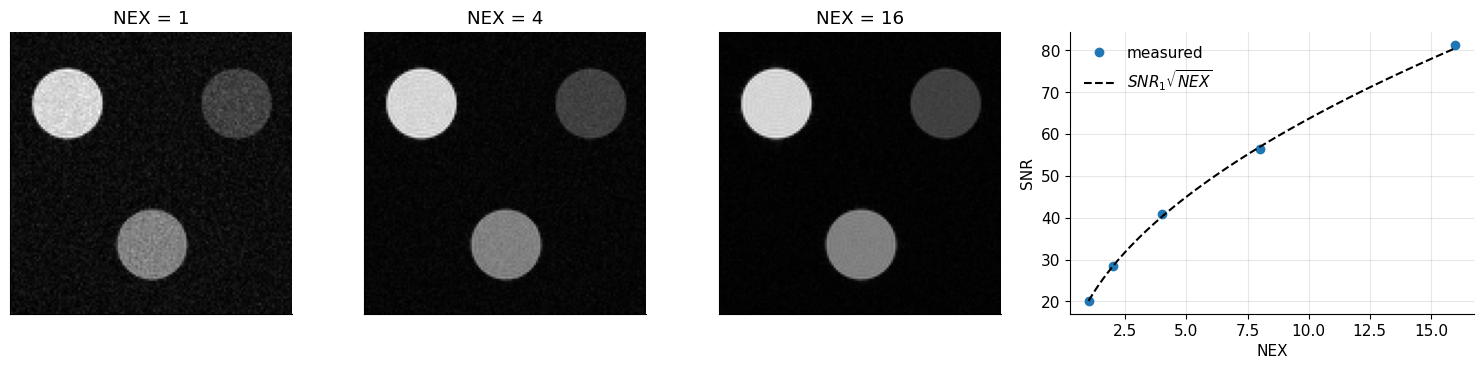

measured SNR: [20.1 28.5 40.8 56.4 81.3]


In [6]:
nex_list = [1, 2, 4, 8, 16]
snr_nex = [snr_complex(acquire(128, NEX=n, rng=np.random.default_rng(10 + n)), 128) for n in nex_list]

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
for a, n in zip(ax[:3], [1, 4, 16]):
    mt.show_image(acquire(128, NEX=n, rng=np.random.default_rng(10 + n)), ax=a, title=f"NEX = {n}", vmin=0, vmax=1.2)
ax[3].plot(nex_list, snr_nex, "o", label="measured")
nn = np.linspace(1, 16, 100)
ax[3].plot(nn, snr_nex[0] * np.sqrt(nn), "k--", label=r"$SNR_1\sqrt{NEX}$")
ax[3].set_xlabel("NEX"); ax[3].set_ylabel("SNR"); ax[3].legend()
plt.tight_layout(); plt.show()
print("measured SNR:", np.round(snr_nex, 1))

The measured SNR follows the $\sqrt{NEX}$ curve: 16 averages (16× the scan time) buy only 4× the SNR – averaging is the most "expensive" way to gain SNR.

### 2. Receiver bandwidth

Theory: at fixed $N_{read}$, $T_{read}=N_{read}/BW_{read}$, so $SNR\propto 1/\sqrt{BW_{read}}$. Halving the bandwidth gains $\sqrt2\approx1.41$ in SNR, but doubles the readout duration (longer minimum TE and TR, more $T_2^*$ decay during the readout, larger chemical-shift displacement and distortion).

In [7]:
bw_list = [0.25, 0.5, 1, 2, 4]          # relative to the reference 64 kHz
snr_bw = [snr_complex(acquire(128, BW_rel=b, rng=np.random.default_rng(20)), 128) for b in bw_list]
BW0 = 64e3                               # reference BW_read [Hz]
N_read = 256                             # for the "scanner" numbers printed below
print(" BW_read   BW_pix(N=256)   T_read   fat shift @3T    SNR (sim)   SNR theory")
for b, s in zip(bw_list, snr_bw):
    BW = b * BW0
    bwpix = BW / N_read
    print(f"{BW/1e3:6.0f} kHz  {bwpix:7.0f} Hz/px   {N_read/BW*1e3:5.1f} ms   {440/bwpix:5.2f} px      "
          f"{s:6.1f}      {snr_bw[2]/np.sqrt(b):6.1f}")

 BW_read   BW_pix(N=256)   T_read   fat shift @3T    SNR (sim)   SNR theory
    16 kHz       62 Hz/px    16.0 ms    7.04 px        40.0        40.1
    32 kHz      125 Hz/px     8.0 ms    3.52 px        28.3        28.3
    64 kHz      250 Hz/px     4.0 ms    1.76 px        20.0        20.0
   128 kHz      500 Hz/px     2.0 ms    0.88 px        14.2        14.2
   256 kHz     1000 Hz/px     1.0 ms    0.44 px        10.0        10.0


Lower bandwidth → higher SNR (∝ $1/\sqrt{BW}$), but the fat–water shift (440 Hz at 3 T divided by $BW_{pix}$) grows in pixels – the classic bandwidth trade-off (see [Artifacts](I2_Artifacts.ipynb)).

### 3. Resolution (matrix size at fixed FOV)

Doubling $N$ in both directions at fixed FOV halves $\delta_x$ and $\delta_y$ (voxel volume ÷4) and doubles both $N_{PE}$ and $N_{read}$ (at fixed $BW_{read}$, $T_{meas}$ ×4). Prediction: $SNR\times\frac14\times\sqrt4 = \frac12$.

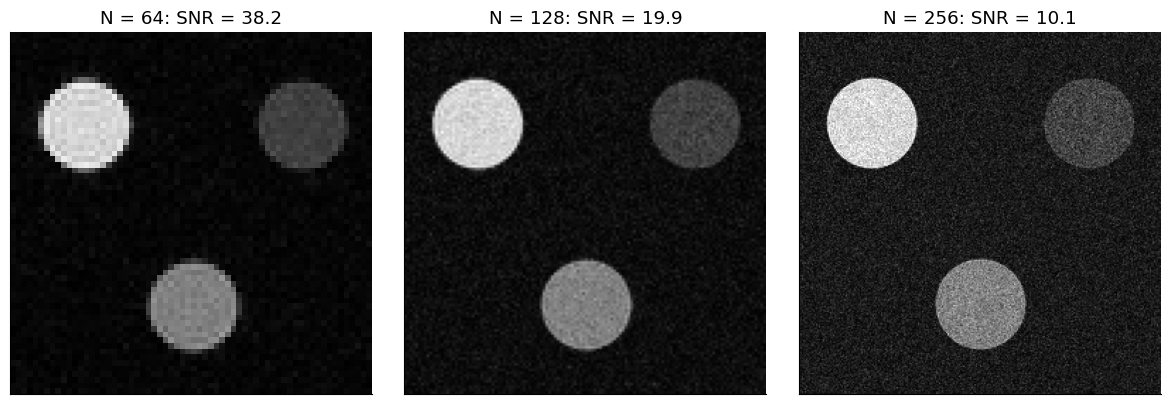

SNR ratios N=64:128:256 = [1.92 1.   0.51]  (theory 2 : 1 : 0.5)


In [8]:
N_list = [64, 128, 256]
imgs = {N: acquire(N, rng=np.random.default_rng(30)) for N in N_list}
snr_N = {N: snr_complex(imgs[N], N) for N in N_list}
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, N in zip(ax, N_list):
    mt.show_image(imgs[N], ax=a, title=f"N = {N}: SNR = {snr_N[N]:.1f}", vmin=0, vmax=1.2)
plt.tight_layout(); plt.show()
print("SNR ratios N=64:128:256 =", np.round([snr_N[N] / snr_N[128] for N in N_list], 2), " (theory 2 : 1 : 0.5)")

The ratios match the prediction: finer resolution is paid for with SNR – the sharpest image (right) is the noisiest. This is the most important trade-off in clinical protocol design.

> **🔧 Engineering reality:** Typical clinical SNR targets are set by the radiologist's task. A 3 T brain T1 at 1 mm isotropic needs ~5 minutes; pushing to 0.5 mm isotropic would cut the voxel volume 8× and would need 64× the scan time to recover the SNR by averaging – impossible in practice. This is why ultra-high resolution needs higher field, better coils, or both.

## SNR efficiency

The SNR efficiency provides a measure of the overall efficiency of an MRI scan: the SNR normalized by the square root of the *total scan time* $T_{scan}$:

$$SNR_{eff} = \frac{SNR}{\sqrt{T_{scan}}} \propto f_{seq}\cdot \Delta V\cdot \sqrt{\frac{T_{meas} }{T_{scan}}}$$

**In words:** how much SNR per $\sqrt{\text{second}}$ of scanner time a sequence produces; the last factor is the **duty cycle**, the fraction of the scan during which the ADC is actually sampling.

where $T_{meas}$ = total sampling time and $T_{scan}$ = total scan time. Dividing by $\sqrt{T_{scan}}$ (not by $T_{scan}$) makes the number independent of how many averages you do, so you can compare sequences fairly. Example: a GRE with $TR=10$ ms and $T_{read}=4$ ms has a duty cycle of 0.4; a bSSFP with $TR=4$ ms and $T_{read}=2.5$ ms has 0.63 and, in addition, a much larger $f_{seq}$ – it is one of the most SNR-efficient sequences.

In [9]:
# Duty cycle & efficiency for a few sequence choices (f_seq from the signal equations; WM at 3 T)
T1, T2, T2s = 0.85, 0.075, 0.050
cases = {
    "spoiled GRE TR=10ms, Ernst":  (10e-3, 4e-3, mt.spoiled_gre_signal(mt.ernst_angle(10e-3, T1), 3e-3, 10e-3, T1, T2s)),
    "bSSFP TR=4ms, 50 deg":        (4e-3, 2.5e-3, mt.bssfp_signal(np.deg2rad(50), 2e-3, 4e-3, T1, T2)),
    "spin echo TR=500ms TE=15ms":  (0.5, 8e-3, mt.spin_echo_signal(15e-3, 0.5, T1, T2)),
}
print(f"{'sequence':30s} {'duty':>6s} {'f_seq':>7s} {'f_seq*sqrt(duty)':>17s}")
for name, (TR_, Tr, f) in cases.items():
    print(f"{name:30s} {Tr/TR_:6.3f} {f:7.3f} {f*np.sqrt(Tr/TR_):17.3f}")

sequence                         duty   f_seq  f_seq*sqrt(duty)
spoiled GRE TR=10ms, Ernst      0.400   0.072             0.046
bSSFP TR=4ms, 50 deg            0.625   0.135             0.106
spin echo TR=500ms TE=15ms      0.016   0.364             0.046


The spin echo has by far the largest signal per TR but spends 98% of its time waiting, so per $\sqrt{\text{time}}$ it is no more efficient than the spoiled GRE; bSSFP wins by more than 2× (at the price of its own contrast and banding artifacts, see [Fast Imaging Pulse Sequences](H2_Fast_Imaging_Pulse_Sequences.ipynb)).

## Resolution and SNR in post-processing

The image resolution is often changed in post-processing: images can be **upsampled** to a finer ("higher") resolution grid or **downsampled** to a coarser ("lower") resolution. When using the SNR equation above, the *acquired* resolution should be considered.

### Upsampling

Upsampling is typically done with some type of interpolation. In MRI, this can easily be implemented in k-space through **zero-padding** (appending zeros around the measured k-space before the inverse FFT), which is equivalent to sinc interpolation in the image ([why: RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)). Upsampling with a reasonable method does not affect SNR – it adds no information, and it also does not add noise. (It does make neighbouring pixels' noise correlated.)

### Downsampling

Downsampling is done to increase SNR by changing the image to a coarser resolution. Downsampling is effectively averaging signals from nearby voxels, which also averages out the noise. Therefore, *downsampling scales SNR as the square root of the voxel-size increase, just like measurement time*: averaging $2\times2$ pixels gives $\sqrt4=2\times$ SNR.

This is a very important distinction from changing the **acquired** resolution, where SNR scales *linearly* with voxel size. Therefore, at the same measurement time, the SNR is higher when acquiring at the desired spatial resolution than when acquiring at a finer resolution and then downsampling. Care should be taken to choose the acquired resolution to match the desired resolution.

The simulation below compares, at **equal $T_{meas}$**:
* **A:** acquire $N=128$, NEX = 1.
* **A↑:** zero-pad A to $256$ (upsampling).
* **A↓:** average $2\times2$ blocks of A → $64\times64$ (downsampling).
* **B:** acquire $N=64$ directly with the same $T_{meas}$: half as many PE lines → NEX = 2; half as many readout samples in the same $T_{read}$ → dwell time doubled → $BW_{read}$ halved.

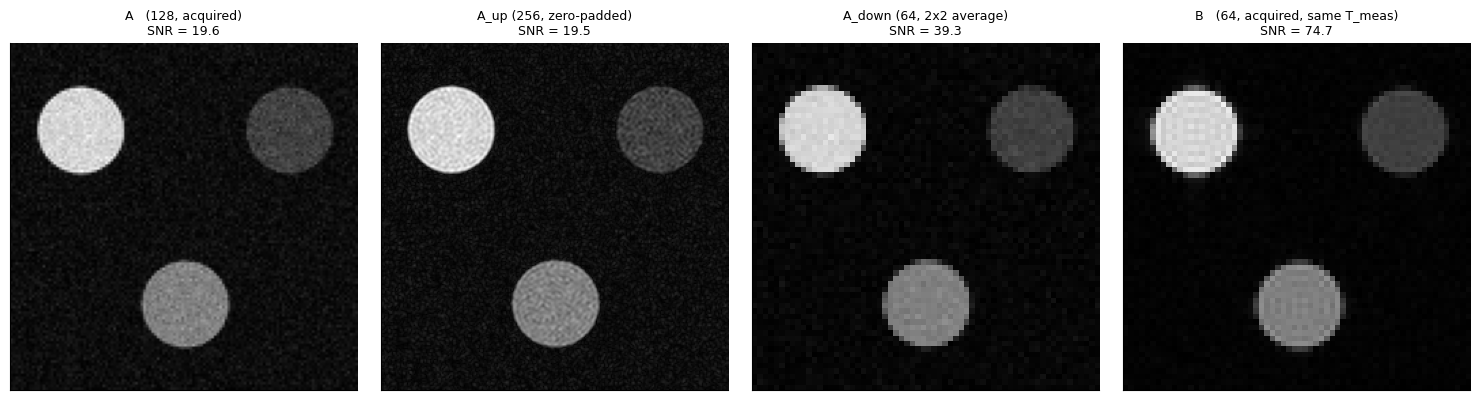

A   (128, acquired)              SNR =  19.6   ratio to A = 1.00
A_up (256, zero-padded)          SNR =  19.5   ratio to A = 1.00
A_down (64, 2x2 average)         SNR =  39.3   ratio to A = 2.01
B   (64, acquired, same T_meas)  SNR =  74.7   ratio to A = 3.82
theory: A_up 1.00, A_down 2.00, B 4.00


In [10]:
rngA, rngB = np.random.default_rng(40), np.random.default_rng(41)
A = acquire(128, rng=rngA)
# upsample by zero-padding k-space (physical scaling: recon = N_new * ifft2c(samples))
sA = mt.fft2c(A / 128)                       # back to physical k-space samples
sA_pad = np.pad(sA, 64)                      # 128 -> 256, zeros outside
A_up = 256 * mt.ifft2c(sA_pad)
A_down = A.reshape(64, 2, 64, 2).mean(axis=(1, 3))     # 2x2 block average
B = acquire(64, NEX=2, BW_rel=0.5, rng=rngB)            # equal T_meas

def snr_any(img):
    return snr_complex(img, img.shape[0])

res = {"A   (128, acquired)": A, "A_up (256, zero-padded)": A_up, "A_down (64, 2x2 average)": A_down,
       "B   (64, acquired, same T_meas)": B}
fig, ax = plt.subplots(1, 4, figsize=(15, 3.9))
for a, (name, im) in zip(ax, res.items()):
    mt.show_image(im, ax=a, title=f"{name}\nSNR = {snr_any(im):.1f}", vmin=0, vmax=1.2)
    a.title.set_fontsize(9)
plt.tight_layout(); plt.show()
for name, im in res.items():
    print(f"{name:32s} SNR = {snr_any(im):5.1f}   ratio to A = {snr_any(im)/snr_any(A):.2f}")
print("theory: A_up 1.00, A_down 2.00, B 4.00")

Zero-padding leaves SNR unchanged (the image only looks smoother), $2\times2$ averaging gives 2×, but acquiring the coarse resolution directly gives 4× – twice as good as downsampling, for the same measurement time.

> **⚠️ Common confusion:** Some scanners zero-pad ("interpolate") by default and display a $512\times512$ image from a $256\times256$ acquisition. The *nominal* pixel size then looks finer than the true resolution, and SNR is that of the $256$ acquisition. Always check the **acquired** matrix.

## Noise in magnitude images: the Rician bias

Clinical images are almost always displayed as **magnitude** images $\lvert\hat m\rvert$, because the phase is affected by coil sensitivities, field inhomogeneity, etc. Taking the magnitude is a non-linear operation that changes the noise statistics:

* In the **background** (true signal $A=0$), $\lvert\hat m\rvert=\sqrt{n_1^2+n_2^2}$ with $n_1,n_2\sim\mathcal N(0,\sigma_n^2)$ follows a **Rayleigh** distribution: it is never negative, has mean $\sigma_n\sqrt{\pi/2}\approx1.253\,\sigma_n$ and standard deviation $\sigma_n\sqrt{(4-\pi)/2}\approx0.655\,\sigma_n$.
* For a true signal $A>0$ it follows a **Rice** distribution

$$p(M\,|\,A,\sigma_n) = \frac{M}{\sigma_n^2}\exp\!\left(-\frac{M^2+A^2}{2\sigma_n^2}\right) I_0\!\left(\frac{A M}{\sigma_n^2}\right),\qquad M\ge0$$

**In words:** the probability of observing magnitude $M$ when the true value is $A$; for large $A/\sigma_n$ it becomes a Gaussian around $\approx\sqrt{A^2+\sigma_n^2}$ with std $\sigma_n$; for $A\to0$ it becomes the Rayleigh distribution.

where $M$ = observed magnitude (here *not* magnetization), $A$ = true amplitude, $\sigma_n$ = noise std per real/imaginary component, $I_0$ = modified Bessel function of order 0 (`scipy.special.i0`). Its mean is

$$\mathbb E[M] = \sigma_n\sqrt{\tfrac{\pi}{2}}\;e^{-x/2}\Big[(1+x)\,I_0\big(\tfrac x2\big)+x\,I_1\big(\tfrac x2\big)\Big],\qquad x=\frac{A^2}{2\sigma_n^2}$$

**In words:** the average magnitude is always *larger* than the true amplitude; the bias is large at low SNR and negligible above SNR ≈ 3–5.

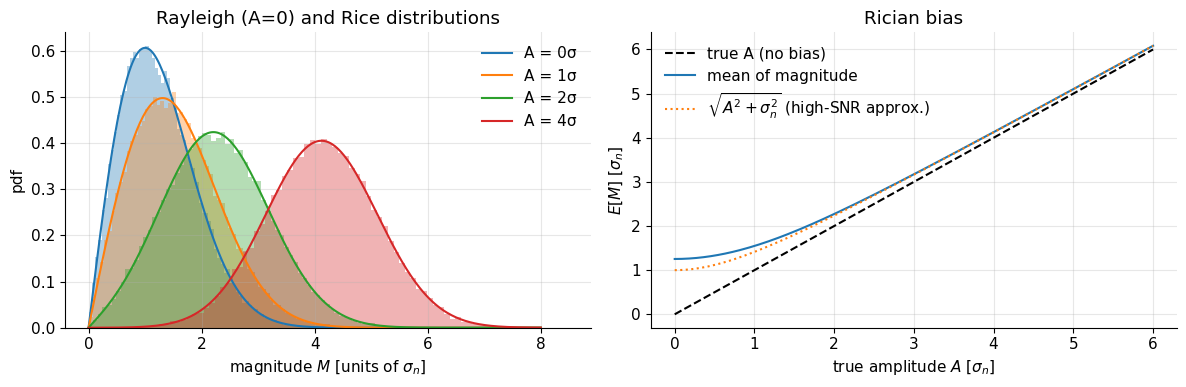

background (A=0): mean = 1.253 sigma (=sqrt(pi/2)), std = 0.655 sigma


In [11]:
from scipy.special import ive   # exponentially scaled modified Bessel function: ive(v, z) = I_v(z) * exp(-z)

def rice_mean(A, sigma):
    x = A**2 / (2 * sigma**2)
    # e^{-x/2} I_v(x/2) = ive(v, x/2)  (numerically stable form)
    return sigma * np.sqrt(np.pi / 2) * ((1 + x) * ive(0, x / 2) + x * ive(1, x / 2))

def rice_pdf(M, A, sigma):
    # (M/s^2) exp(-(M^2+A^2)/(2 s^2)) I0(AM/s^2) = (M/s^2) exp(-(M-A)^2/(2 s^2)) ive(0, AM/s^2)
    return M / sigma**2 * np.exp(-(M - A) ** 2 / (2 * sigma**2)) * ive(0, A * M / sigma**2)

rng = np.random.default_rng(5)
sigma = 1.0
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
Mgrid = np.linspace(0, 8, 300)
for A_true, col in [(0, "C0"), (1, "C1"), (2, "C2"), (4, "C3")]:
    samples = np.abs(mt.add_complex_noise(np.full(50000, A_true, complex), sigma, rng=rng))
    ax[0].hist(samples, 80, density=True, alpha=0.35, color=col)
    ax[0].plot(Mgrid, rice_pdf(Mgrid, A_true, sigma), color=col, label=f"A = {A_true}σ")
ax[0].set_xlabel(r"magnitude $M$ [units of $\sigma_n$]"); ax[0].set_ylabel("pdf"); ax[0].legend()
ax[0].set_title("Rayleigh (A=0) and Rice distributions")
A_axis = np.linspace(0, 6, 200)
ax[1].plot(A_axis, A_axis, "k--", label="true A (no bias)")
ax[1].plot(A_axis, rice_mean(A_axis, sigma), label="mean of magnitude")
ax[1].plot(A_axis, np.sqrt(A_axis**2 + sigma**2), ":", label=r"$\sqrt{A^2+\sigma_n^2}$ (high-SNR approx.)")
ax[1].set_xlabel(r"true amplitude $A$ [$\sigma_n$]"); ax[1].set_ylabel(r"$E[M]$ [$\sigma_n$]"); ax[1].legend()
ax[1].set_title("Rician bias")
plt.tight_layout(); plt.show()
print(f"background (A=0): mean = {rice_mean(0, 1):.3f} sigma (=sqrt(pi/2)), std = {np.sqrt((4-np.pi)/2):.3f} sigma")

Histograms (simulated) and formulas (lines) agree. At $A=0$ the magnitude still averages $1.25\,\sigma_n$ – noise alone produces a "signal floor". This matters for any quantitative measurement at low SNR (e.g. fitting a $T_2$ decay or diffusion signal down into the noise: the curve flattens at the noise floor instead of going to zero).

> **📐 Math note:** A simple bias correction for a region of pixels is $\hat A^2 \approx \overline{M^2} - 2\sigma_n^2$, because $\mathbb E[M^2]=A^2+2\sigma_n^2$ exactly (sum of the squares of two Gaussians with means $A$, $0$).

## Measuring SNR in practice

Because the true noise is invisible in a single magnitude image, several methods are in use (see e.g. Dietrich et al., *J Magn Reson Imaging* 2007, and the NEMA MS 1 standard):

| Method | How | Correction | Pitfalls |
|---|---|---|---|
| **Two-region, std of background** | mean of signal ROI / std of an empty background ROI in the *magnitude* image | divide background std by 0.655 (Rayleigh) | background must be truly empty: no ghosts, no aliasing; fails with parallel imaging / multi-coil (non-uniform noise) |
| **Two-region, mean of background** | mean of signal ROI / mean of background ROI | divide background mean by 1.253 | same; also biased by any DC offset |
| **Difference of two images** | scan twice, identical; noise std = std(image₁ − image₂) in the signal ROI / $\sqrt2$ | $\sqrt2$, because the difference has twice the noise variance | needs two scans; any motion between them inflates noise |
| **Multiple replicas** | scan (or simulate by adding noise to raw data) many times; pixel-wise mean / pixel-wise std | none | slowest, but gives an SNR **map** and works with any reconstruction (gold standard) |
| **Complex background (simulation, raw data)** | std of the real part of background | none | only possible with complex data |

true sigma_n = 0.0500, true SNR = 20.0
complex background (reference)               sigma = 0.0488   SNR =   20.4
magnitude bg std, uncorrected                sigma = 0.0328   SNR =   30.4
magnitude bg std / 0.655                     sigma = 0.0500   SNR =   19.9
magnitude bg mean / 1.253                    sigma = 0.0493   SNR =   20.3
difference of two images / sqrt2             sigma = 0.0493   SNR =   20.2
multiple replicas (mean of std map in ROI)   sigma = 0.0493   SNR =   20.3


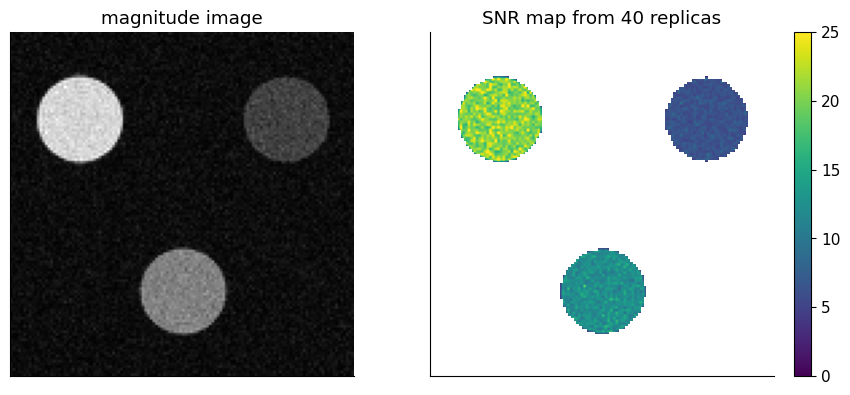

In [12]:
N = 128
sig, bg = masks(N)
rng = np.random.default_rng(7)
truth_sigma_n = 0.05 * N / 128                      # known image noise std of our virtual scanner
img1 = acquire(N, rng=rng); img2 = acquire(N, rng=rng)
mag1, mag2 = np.abs(img1), np.abs(img2)
S = mag1[sig].mean()

est = {
    "complex background (reference)": img1.real[bg].std(),
    "magnitude bg std, uncorrected":   mag1[bg].std(),
    "magnitude bg std / 0.655":        mag1[bg].std() / np.sqrt((4 - np.pi) / 2),
    "magnitude bg mean / 1.253":       mag1[bg].mean() / np.sqrt(np.pi / 2),
    "difference of two images / sqrt2": (mag1 - mag2)[sig].std() / np.sqrt(2),
}
reps = np.stack([np.abs(acquire(N, rng=rng)) for _ in range(40)])     # 40 replicas
snr_map = reps.mean(0) / reps.std(0)
est["multiple replicas (mean of std map in ROI)"] = reps.std(0)[sig].mean()

print(f"true sigma_n = {truth_sigma_n:.4f}, true SNR = {1/truth_sigma_n:.1f}")
for k, v in est.items():
    print(f"{k:44s} sigma = {v:.4f}   SNR = {S / v:6.1f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
mt.show_image(mag1, ax=ax[0], title="magnitude image", vmin=0, vmax=1.2)
im = ax[1].imshow(np.where(np.abs(reps.mean(0)) > 0.15, snr_map, np.nan), cmap="viridis", vmin=0, vmax=25)
ax[1].set_title("SNR map from 40 replicas"); ax[1].set_xticks([]); ax[1].set_yticks([]); ax[1].grid(False)
plt.colorbar(im, ax=ax[1], fraction=0.046); plt.tight_layout(); plt.show()

Without the Rayleigh correction the background std underestimates the noise by about 35% (SNR overestimated by ~50%); all corrected methods agree with the truth (SNR 20). The replica SNR map shows SNR ∝ signal: the 0.6 and 0.3 disks have 60% and 30% of the bright disk's SNR.

> **🔧 Engineering reality:** With multi-channel coil arrays and parallel imaging, noise is **not** uniform across the image (sum-of-squares combination and g-factor make it vary in space), and the background statistics become non-central chi rather than Rayleigh. Many scanners also mask or filter the background. The two-region method then fails; vendors and researchers use replica methods ("pseudo-multiple replica", Robson et al. 2008). See [Advanced SNR](J4_Advanced_SNR.ipynb).

## System factors: field strength and coils

### Field strength

How does SNR scale with $B_0$? Follow the signal chain:

1. **Magnetization:** $M_0\propto B_0$ (more spins align at higher field – Boltzmann/Curie law, see [Spin and thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)).
2. **Induced voltage:** Faraday's law – the voltage is proportional to the rate of change of the flux, i.e. to $\omega_0\cdot M_0$. Since $\omega_0\propto B_0$: **signal $\propto B_0^2$**.
3. **Noise:** $v_n=\sqrt{4k_BT R_{tot}BW_{read}}$, so it depends on how $R_{tot}$ grows with frequency:
   * **Body noise** (induced eddy currents in tissue): $R_{body}\propto\omega_0^2$ → $v_n\propto\omega_0\propto B_0$.
   * **Coil noise** (copper, skin effect): $R_{coil}\propto\sqrt{\omega_0}$ → $v_n\propto\omega_0^{1/4}$.

Hence

$$SNR\propto\frac{B_0^2}{\sqrt{a\,B_0^{1/2}+b\,B_0^{2}}}\;\approx\;\begin{cases}B_0^{7/4} & \text{coil-noise dominated (low field, small coils)}\\ B_0 & \text{body-noise dominated (≥1.5 T, human-size coils)}\end{cases}$$

**In words:** signal grows quadratically with field; noise grows too, linearly once the patient is the dominant noise source, so the net gain is roughly linear: 3 T gives about twice the SNR of 1.5 T.

where $a$, $b$ are constants describing the coil and the body.

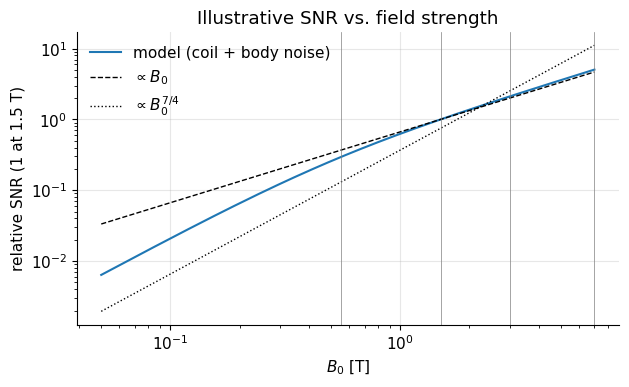

SNR(3T)/SNR(1.5T) = 2.11   SNR(7T)/SNR(3T) = 2.39


In [13]:
B0 = np.linspace(0.05, 7, 400)
a, b = 1.0, 1.0 / 0.5**1.5   # constants chosen so coil and body noise are equal at ~0.5 T (illustrative)
snr = B0**2 / np.sqrt(a * B0**0.5 + b * B0**2)
snr /= np.interp(1.5, B0, snr)
plt.figure(figsize=(7, 3.8))
plt.loglog(B0, snr, label="model (coil + body noise)")
plt.loglog(B0, (B0 / 1.5), "k--", lw=1, label=r"$\propto B_0$")
plt.loglog(B0, (B0 / 1.5) ** 1.75 * 0.75, "k:", lw=1, label=r"$\propto B_0^{7/4}$")
for f in [0.55, 1.5, 3, 7]:
    plt.axvline(f, color="gray", lw=0.5)
plt.xlabel(r"$B_0$ [T]"); plt.ylabel("relative SNR (1 at 1.5 T)"); plt.legend()
plt.title("Illustrative SNR vs. field strength"); plt.show()
print("SNR(3T)/SNR(1.5T) =", round(np.interp(3, B0, snr) / np.interp(1.5, B0, snr), 2),
      "  SNR(7T)/SNR(3T) =", round(np.interp(7, B0, snr) / np.interp(3, B0, snr), 2))

Above ~1 T the curve follows the linear law; at low field (e.g. 0.55 T or below) it is steeper, which is why low-field systems rely heavily on optimized coils and longer acquisitions.

> **⚠️ Common confusion:** "3 T doubles the SNR" is only the **baseline** gain. In practice it is partly spent or lost: $T_1$ gets longer at higher field (lower $f_{seq}$ for the same TR), the chemical shift in Hz doubles (so people double $BW_{read}$, losing $\sqrt2$), SAR grows ∝ $B_0^2$ (limiting flip angles and TR, see [MRI Safety](B6_MRI_Safety.ipynb)), and at 3 T and especially 7 T the RF wavelength in tissue becomes comparable to the body, causing $B_1^+$ inhomogeneity (see [RF System](B5_RF_System_and_Receive_Chain.ipynb)). Measured clinical gains from 1.5 T to 3 T are therefore often clearly below 2× (roughly 1.5–1.9×, depending on sequence and coil).

### RF coils

The receive coil sets the proportionality constant of the SNR equation:

* **Small coils close to the anatomy** see the signal strongly but "see" only a small volume of noisy tissue → high SNR near the coil (surface coils), falling off with depth.
* **Coil arrays** (8–64+ small elements, each with its own receiver) combine the high local SNR of small coils with the coverage of a large coil. Combined with sum-of-squares or optimal (Roemer) combination, they give SNR gains of 2–5× over a body coil, most near the surface (see [Image Reconstruction](F3_Image_Reconstruction.ipynb) for the combination).
* Arrays also allow **parallel imaging** (fewer phase encodes), which reduces SNR by $g\sqrt R$ ($R$ = acceleration factor, $g\ge1$ = geometry factor). See [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb).
* Cooling the coil (cryogenic coils, used in animal scanners) only helps when coil noise dominates – i.e. small coils and low field.

> **🔧 Engineering reality:** The whole receive chain is designed to add as little noise as possible to the body noise: preamplifiers with noise figure ≈ 0.5 dB, placed directly at the coil; preamplifier decoupling to stop array elements from coupling noise into each other; and an ADC with enough dynamic range to digitize the huge k-space center and the tiny edges. See [RF System and Receive Chain](B5_RF_System_and_Receive_Chain.ipynb).

## Try it yourself (interactive)

Change matrix size, bandwidth and NEX of the virtual scanner and compare the predicted SNR change ($\propto \Delta V\sqrt{T_{meas}}$) with the measured one. A static version for the default values is shown first.

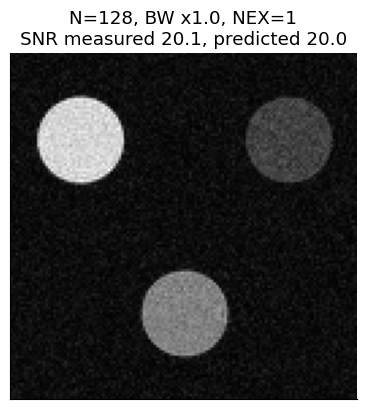

In [14]:
def compare(N=128, BW_rel=1.0, NEX=1):
    img = acquire(N, BW_rel=BW_rel, NEX=NEX, rng=np.random.default_rng(99))
    meas = snr_complex(img, N)
    # prediction relative to reference (N=128, BW_rel=1, NEX=1, SNR=20):
    dV = (128 / N) ** 2                                  # voxel area ratio
    Tm = (N / 128) * NEX * (N / 128) / BW_rel            # N_PE * NEX * N_read / BW_read
    pred = 20 * dV * np.sqrt(Tm)
    plt.figure(figsize=(4.5, 4.5))
    mt.show_image(img, title=f"N={N}, BW x{BW_rel}, NEX={NEX}\nSNR measured {meas:.1f}, predicted {pred:.1f}",
                  vmin=0, vmax=1.2)
    plt.show()

compare()   # static default

In [15]:
try:
    from ipywidgets import interact, IntSlider, FloatLogSlider, Dropdown
    interact(compare, N=Dropdown(options=[64, 128, 256], value=128),
             BW_rel=FloatLogSlider(value=1, base=2, min=-2, max=2, step=1), NEX=IntSlider(value=1, min=1, max=8))
except ImportError:
    print("ipywidgets not available - use compare(N, BW_rel, NEX) directly.")

interactive(children=(Dropdown(description='N', index=1, options=(64, 128, 256), value=128), FloatLogSlider(va…

## Key takeaways

* $T_{scan}=TR\cdot N_{TR}$, and for unaccelerated 2D Cartesian imaging $N_{TR}=N_{PE}\cdot NEX$ (readout samples do **not** add TRs).
* MRI noise is thermal, mostly from the patient's conductive tissue at ≥1.5 T; it is complex, Gaussian, white, with variance ∝ receiver bandwidth.
* $SNR\propto f_{seq}\cdot\Delta V\cdot\sqrt{T_{meas}}$: linear in voxel volume, square root in sampling time ($\sqrt{NEX}$, $1/\sqrt{BW}$).
* Acquiring at the desired resolution beats acquiring finer and downsampling (linear vs. square-root gain); zero-padding does not change SNR.
* Magnitude images are Rician: the background has mean $1.253\sigma_n$ and std $0.655\sigma_n$; correct for this when measuring SNR, and beware of the noise floor in quantitative fits.
* SNR grows roughly ∝ $B_0$ (body-noise regime) and strongly depends on the coil; the practical 1.5→3 T gain is less than 2× because of $T_1$, bandwidth and SAR changes.

## Check your understanding

1. A protocol has $TR=600$ ms, $N_{PE}=256$, NEX = 2. How long is the scan? What happens to scan time and SNR if you set NEX = 1 and $N_{PE}=192$ at the same FOV?

<details><summary>Answer</summary>

$T_{scan}=0.6\cdot256\cdot2=307$ s ≈ 5.1 min. New: $0.6\cdot192\cdot1=115$ s. SNR: $\delta_y$ grows by $256/192=1.33$ (voxel ×1.33), $T_{meas}$ falls by $192/(256\cdot 2)=0.375$ → $\sqrt{0.375}=0.61$; total SNR factor $1.33\cdot0.61\approx0.82$.

</details>

2. You halve the receiver bandwidth. By how much does SNR change, and what are two disadvantages?

<details><summary>Answer</summary>

$SNR\times\sqrt2\approx1.41$ (noise variance ∝ BW). Disadvantages: the readout doubles in length (longer minimum TE/TR, more $T_2^*$ decay and blurring during the readout), and the chemical-shift and off-resonance displacements in pixels double.

</details>

3. Why is the standard deviation of the background in a magnitude image *not* the noise level $\sigma_n$?

<details><summary>Answer</summary>

Because the magnitude of zero-mean complex Gaussian noise is Rayleigh distributed, never negative; its std is $\sqrt{(4-\pi)/2}\,\sigma_n\approx0.655\sigma_n$ (and its mean $1.253\sigma_n$). Use the correction factor, or use the difference / replica methods.

</details>

4. Image A is acquired with $2\times2$ mm pixels; image B with $1\times1$ mm pixels and then $2\times2$-averaged. Same $T_{meas}$. Which has higher SNR, and by how much?

<details><summary>Answer</summary>

A. Acquired voxel area is 4× larger → SNR ×4 relative to B's original acquisition; averaging $2\times2$ pixels of B only gives $\sqrt4=2$×. So A has 2× the SNR of the downsampled B.

</details>

5. Why does SNR grow only ~linearly with $B_0$, although the signal grows with $B_0^2$?

<details><summary>Answer</summary>

Because the dominant noise source, the patient's conductive tissue, couples more strongly at higher frequency: $R_{body}\propto\omega_0^2$, so the noise voltage $\propto\omega_0\propto B_0$. $B_0^2/B_0=B_0$.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Signal to Noise Ratio". Changes: added physical noise sources (Johnson noise, body vs. coil noise), the √N derivation, Python simulations of averaging/bandwidth/resolution/post-processing, Rician statistics and SNR measurement methods, field-strength and coil dependence; corrected $N_{TR}=N_{PE}\cdot NEX$ (original multiplied by $N_{FE}$), "relaxation rates" → time constants, added the $e^{-TE/T_2^*}$ factor to $f_{seq,GRE}$, clarified total vs. one-sided bandwidth, fixed typos.*